# 05 — Gradient Boosting vs Random Forest (Supporting Exercise)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

- **Random Forest** (`04_random_forest_review.ipynb`) builds many trees **independently** and averages them.
- **Gradient Boosting** builds trees **one after another**: each new tree tries to improve the mistakes made by the previous trees.

The goal is to compare Gradient Boosting with Random Forest using exactly the same data.

- **Target:** `duration_days`, the recorded activity span (same as before)
- **Features:** `events_per_case`, `unique_activities`, `unique_resources` (same as before)

## 2. Same Data

Same dataset and same completed-case logic as the previous notebooks.

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))

Completed cases: 956


> **Supporting experiment.** These features describe the **whole finished case**, so they are only known after the
> case ends. This is a regression learning exercise, **not** an early-warning model.

In [3]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

## 3. Same Train/Test Split

Exactly the same split as before, so all models are tested on the same 192 cases.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 4. Gradient Boosting Model

- `n_estimators=100`: the model builds **100 small trees**.
- `learning_rate=0.05`: each new tree makes only a **small correction**.
- `max_depth=2`: each individual tree stays **simple**.

In [5]:
model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 5. Evaluation

Same metrics as before: **MAE**, **RMSE** and **R²**, plus training R² vs test R².

In [6]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)


print(f"Gradient Boosting MAE: {mae:.2f} days")
print(f"Gradient Boosting RMSE: {rmse:.2f} days")
print(f"Gradient Boosting R²: {r2:.2f}")

Gradient Boosting MAE: 51.19 days
Gradient Boosting RMSE: 104.63 days
Gradient Boosting R²: 0.49


## 6. Negative Predictions

In [7]:
print("Predictions below zero:", (y_pred < 0).sum())
print(f"Minimum predicted duration: {y_pred.min():.2f} days")

Predictions below zero: 0
Minimum predicted duration: 38.06 days


## 7. Feature Importance

Feature importance shows which variables the trees used most when making their splits. It does **not** mean that a feature
*causes* longer or shorter cases.

In [8]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})
importance

,feature,importance
0,events_per_case,0.797965
1,unique_activities,0.141485
2,unique_resources,0.060549


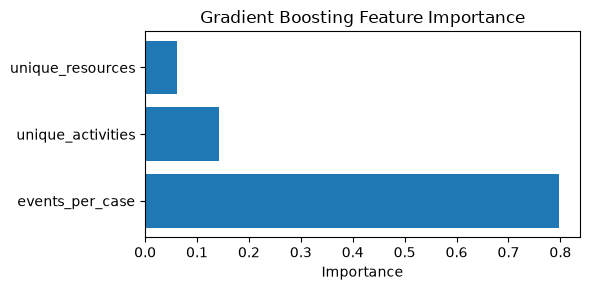

In [9]:
plt.figure(figsize=(6, 3))
plt.barh(importance["feature"], importance["importance"])
plt.title("Gradient Boosting Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Actual vs Predicted

Points on the dashed line would be perfect predictions.

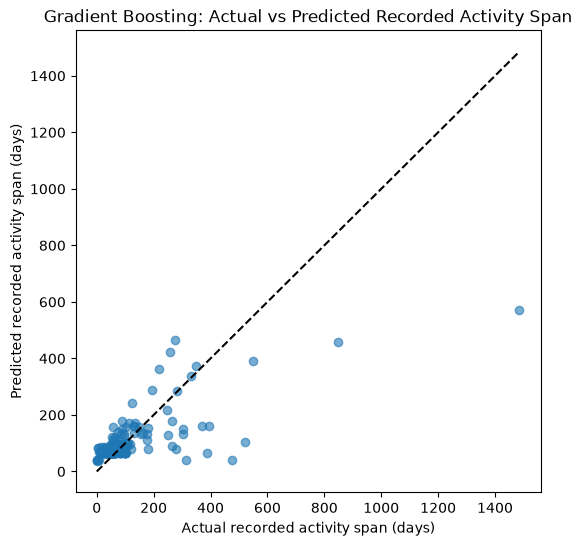

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
plt.title("Gradient Boosting: Actual vs Predicted Recorded Activity Span")
plt.xlabel("Actual recorded activity span (days)")
plt.ylabel("Predicted recorded activity span (days)")
plt.show()

## 9. Compare All Models

Same 764 training and 192 test cases for every approach. The earlier models are trained again here with the same settings
as notebooks 02–04, so no results are copied by hand. **Train R²** is shown next to test R² to check for overfitting.

In [11]:
linear_model = LinearRegression().fit(X_train, y_train)
tree_model = DecisionTreeRegressor(max_depth=4, random_state=42).fit(X_train, y_train)
forest_model = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42).fit(X_train, y_train)

mean_train = [y_train.mean()] * len(y_train)
median_train = [y_train.median()] * len(y_train)
approaches = [
    ("Mean baseline", mean_train, [y_train.mean()] * len(y_test)),
    ("Median baseline", median_train, [y_train.median()] * len(y_test)),
    ("Linear Regression", linear_model.predict(X_train), linear_model.predict(X_test)),
    ("Decision Tree", tree_model.predict(X_train), tree_model.predict(X_test)),
    ("Random Forest", forest_model.predict(X_train), forest_model.predict(X_test)),
    ("Gradient Boosting", model.predict(X_train), y_pred),
]

**Compare all approaches on the same 192 test cases.** The loop calculates the same metrics for each approach; Train R² is shown next to Test R² as a simple check for overfitting.

In [12]:
# the same metrics for every approach, on the same 192 test cases
rows = []
for name, pred_train, pred_test in approaches:
    rows.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": mean_squared_error(y_test, pred_test) ** 0.5,
        "Test R²": r2_score(y_test, pred_test),
        "Train R²": r2_score(y_train, pred_train),
    })
comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(2)

,Test MAE,Test RMSE,Test R²,Train R²
Model,,,,
Mean baseline,71.98,147.26,-0.00,0.00
Median baseline,64.42,153.00,-0.08,-0.09
Linear Regression,59.01,126.02,0.26,0.18
Decision Tree,58.73,125.50,0.27,0.52
Random Forest,52.00,109.60,0.44,0.52
Gradient Boosting,51.19,104.63,0.49,0.46


## 10. Simple Interpretation

1. **Did Gradient Boosting beat Random Forest on MAE?** Only slightly: 51.19 vs 52.00 days, less than one day better.
2. **Did it beat Random Forest on RMSE?** Yes: 104.63 vs 109.60 days, so it makes somewhat smaller large errors.
3. **Did it improve R²?** A little: 0.49 vs 0.44. It explains about half of the variation in the recorded activity span.
4. **What is the train/test gap?** Training R² 0.46 vs test R² 0.49. On this split, test performance is not worse than
   training performance, which is a good sign. Test R² being slightly higher than training R² is most likely luck of this
   particular 192-case test set, and one split cannot prove that the model would work as well on other cases.
5. **Are there negative predictions?** No. The lowest prediction is 38.06 days.
6. **Which feature is most important?** `events_per_case` (about 0.80), then `unique_activities` (about 0.14) and
   `unique_resources` (about 0.06). This shows what the model used, not what causes long cases.
7. **Is the improvement meaningful or small?** **Small.** Gradient Boosting is the best model on this test set, but the
   gain over Random Forest is much smaller than the earlier jump from one Decision Tree to Random Forest. The longest
   cases are still strongly under-predicted (the 1,486-day case is predicted at about 570 days).

## 11. Conclusion of the Whole-Case Exercises (Notebooks 02–05)

| Step | What I learned (test MAE in days) |
|---|---|
| Median baseline → Linear Regression | The three features contain some information (64.42 → 59.01). |
| Linear Regression → Decision Tree | One simple tree gives almost the same result (58.73) and overfits. |
| Decision Tree → Random Forest | Averaging many trees gives a clearer gain (52.00; R² 0.27 → 0.44). |
| Random Forest → Gradient Boosting | Only a small further gain (51.19; R² 0.44 → 0.49). |

- The ensemble models (Random Forest, Gradient Boosting) did better than the simple models **on this split**.
- Even the best model still makes large errors on long cases (RMSE about 105 days).
- These results come from **one** random train/test split, and the features describe the **complete finished case**, so
  they cannot be used for early warning.

## 12. Next Step

Move to features that exist **before** the case is finished: notebook 06 (first five events) and notebooks 07–12
(fixed day-14 and day-30 snapshots).